# LLM Complexity — interactive NVIDIA tutorial

Measure how algorithmic difficulty and input length independently affect NVIDIA NIM responses. Three tasks have exact Python oracles: pointer chasing, modular arithmetic, and type-matched brackets.

No public paper or canonical source repository has been verified for this project. This is an explicitly independent controlled-task demonstration, not a claimed reproduction of an unpublished result.

Start with the visibly selected fixture mode. Switch to live only after configuring your own key.

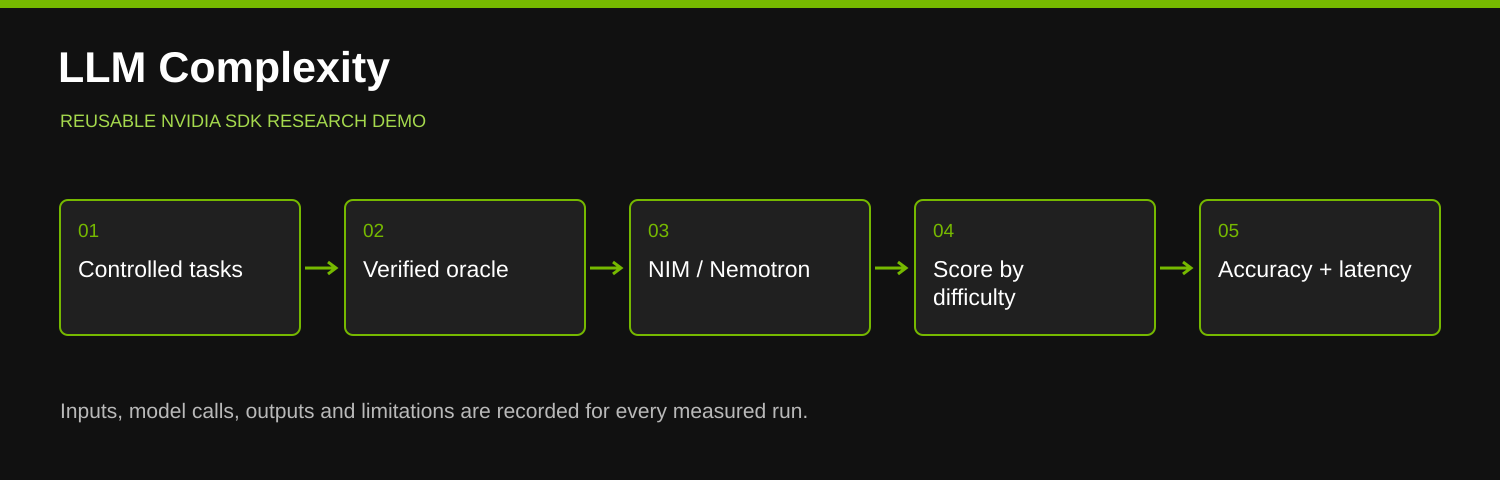

In [1]:
from pathlib import Path
import sys, subprocess, os
# Clone includes figures and saved evaluation inputs as well as the Python package.
if not Path("project_demo").is_dir():
    checkout=Path("llm-complexity-nvidia")
    if not checkout.exists():
        subprocess.check_call(["git","clone","https://github.com/virginiakm1988/llm-complexity-nvidia.git",str(checkout)])
    os.chdir(checkout)
    subprocess.check_call([sys.executable,"-m","pip","install",".[designer,tokenizer,tutorial]"])
from project_demo import core
from project_demo.runtime import save_json, save_jsonl, manifest
import json, uuid
import ipywidgets as widgets
from IPython.display import display, Markdown, SVG
display(SVG(filename="figures/overview.svg"))


In [2]:
# Optional, live mode only. This cell never prints or stores credentials.
import os
try:
    from google.colab import userdata
    key = userdata.get("NVIDIA_API_KEY")
    if key: os.environ["NVIDIA_API_KEY"] = key
except (ImportError, Exception):
    pass


## Experiment controls

Change one factor at a time. The sample slider bounds a tutorial run; use configuration files for larger comparisons.

In [3]:
mode = widgets.Dropdown(options=["fixture", "live"], value="fixture", description="Run mode")
sample_count = widgets.IntSlider(value=1,min=1,max=3,description="Samples")
custom_note = widgets.Textarea(value="",description="Run note",placeholder="Describe the factor you want to compare")
config_overrides = widgets.Textarea(value="{}", description="Config JSON", placeholder='Example: {"seed": 123}')
button = widgets.Button(description="Run example",button_style="success")
panel = widgets.Output()
display(mode,sample_count,config_overrides,custom_note,button,panel)


Dropdown(description='Run mode', options=('fixture', 'live'), value='fixture')

IntSlider(value=1, description='Samples', max=3, min=1)

Textarea(value='{}', description='Config JSON', placeholder='Example: {"seed": 123}')

Textarea(value='', description='Run note', placeholder='Describe the factor you want to compare')

Button(button_style='success', description='Run example', style=ButtonStyle())

Output()

In [4]:
def run_example(_=None):
    with panel:
        panel.clear_output()
        config=dict(core.DEFAULT_CONFIG)
        config["replicates"]=sample_count.value
        config["limit_per_task"]=sample_count.value
        if "difficulties" in config: config["difficulties"]=[1,5]
        config.update(json.loads(config_overrides.value))
        output=Path("runs")/("interactive-"+uuid.uuid4().hex[:10])
        output.mkdir(parents=True)
        try:
            rows=core.prepare(config,mode.value,output)
            save_jsonl(output/"dataset.jsonl",rows)
            predictions=core.run(config,rows,mode.value,output)
            save_jsonl(output/"predictions.jsonl",predictions)
            status="completed_with_errors" if any(r.get("error") or r.get("judge_errors") for r in predictions) else "completed"
            meta=manifest(config,mode.value,rows,status)
            meta["user_note"]=custom_note.value
            save_json(output/"run_manifest.json",meta)
            metrics=core.evaluate(predictions,config)
            metrics["result_kind"]=meta["result_kind"]
            save_json(output/"metrics.json",metrics)
            display(Markdown("**Evidence:** `"+str(output)+"`"))
            print(json.dumps(metrics,ensure_ascii=False,indent=2))
            display(Markdown("**First example:**"))
            print(json.dumps(predictions[0],ensure_ascii=False,indent=2)[:2200])
        except Exception as exc:
            save_json(output/"failure.json",{"type":type(exc).__name__,"message":str(exc),"mode":mode.value})
            print(type(exc).__name__+": "+str(exc))
button.on_click(run_example)
run_example()  # Uses the visible default mode; never overrides your selection.


In [5]:
# A plain saved-output view remains readable without widget state.
from project_demo.runtime import read_jsonl
saved = sorted(Path("runs").glob("interactive-*/metrics.json"), key=lambda p: p.stat().st_mtime)
if saved:
    latest = saved[-1].parent
    print("Saved run:", latest.name)
    print((latest/"metrics.json").read_text(encoding="utf-8"))
    examples=read_jsonl(latest/"predictions.jsonl")
    selected=widgets.Dropdown(options=[(r["id"],i) for i,r in enumerate(examples)],description="Example")
    detail=widgets.Output()
    def inspect(change=None):
        with detail:
            detail.clear_output()
            row=examples[selected.value]
            display(Markdown("**Source input and saved response**"))
            print(json.dumps({k:row[k] for k in ["question","payload","record","prediction","answer","error"] if k in row},ensure_ascii=False,indent=2)[:5000])
    selected.observe(inspect,names="value")
    display(selected,detail)
    inspect()


Saved run: interactive-69b6512908
{
  "conditions": [
    {
      "model": "nvidia/nemotron-3.5-lightning-30b-a3b",
      "thinking": false,
      "task": "arithmetic",
      "difficulty": 1,
      "length": 1024,
      "n": 1,
      "correct": 1,
      "accuracy": 1.0,
      "wilson95": [
        0.20654329147389294,
        1
      ],
      "mean_seconds": 7.3998235166072845e-06,
      "errors": 0
    },
    {
      "model": "nvidia/nemotron-3.5-lightning-30b-a3b",
      "thinking": false,
      "task": "arithmetic",
      "difficulty": 1,
      "length": 2048,
      "n": 1,
      "correct": 1,
      "accuracy": 1.0,
      "wilson95": [
        0.20654329147389294,
        1
      ],
      "mean_seconds": 5.200039595365524e-06,
      "errors": 0
    },
    {
      "model": "nvidia/nemotron-3.5-lightning-30b-a3b",
      "thinking": false,
      "task": "arithmetic",
      "difficulty": 5,
      "length": 1024,
      "n": 1,
      "correct": 1,
      "accuracy": 1.0,
      "wilson95": 

Dropdown(description='Example', options=(('pointer-r0-d1-n1024', 0), ('pointer-r0-d1-n2048', 1), ('pointer-r0-…

Output()

## Interpret and reuse

The tasks are synthetic. Success or failure does not prove a complexity class limitation. Small runs have wide uncertainty intervals; the fixed tokenizer controls body tokens, not hidden server chat-template overhead.

Reuse the package API and config files for your own group. Keep original test splits separate from any training data.